# Capítulo 5 · Actividad: ¿cuánto consume este auto?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/riosinda/ml-course/blob/main/notebooks/exercises/chapter_05/02_actividad_mpg_regresion.ipynb)

Entrena una **regresión** que prediga el rendimiento de un auto en **millas por galón** (`mpg`) y consigue el mejor modelo que puedas. Haz todo el proceso que vimos en clase; el preprocesamiento lo decides tú.

| Variable | Significado |
|---|---|
| `mpg` | **Target**: millas por galón (más alto = consume menos) |
| `cylinders` | Número de cilindros |
| `displacement` | Cilindrada del motor (pulgadas cúbicas) |
| `horsepower` | Potencia (caballos de fuerza) |
| `weight` | Peso (libras) |
| `acceleration` | Segundos para ir de 0 a 60 mph |
| `model_year` | Año del modelo (70 = 1970) |
| `origin` | Región de origen: `usa`, `europe` o `japan` |
| `name` | Nombre del auto |

Como mínimo, tu notebook debe incluir:

- Un **modelo lineal base**: coeficientes, métricas de error y $R^2$.
- Los mismos modelos que vimos en clase: regresión simple, lineal múltiple, Ridge, Lasso, polinomial y RANSAC.
- Una **tabla final** comparando los modelos con validación cruzada y test, y tus **conclusiones**: ¿qué modelo elegirías y por qué?

1. **Copia esta notebook a `workspace/`** y trabaja sobre la copia.
2. Si todavía no tienes los datos: `uv run python scripts/download_data.py`

In [70]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import RANSACRegressor
from sklearn.model_selection import GridSearchCV

# Carpeta data/ en la raíz del repo: subimos de carpeta en carpeta hasta dar con pyproject.toml
raiz = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), Path.cwd())
DATA_DIR = raiz / "data"

df = pd.read_csv(DATA_DIR / "mpg.csv")
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


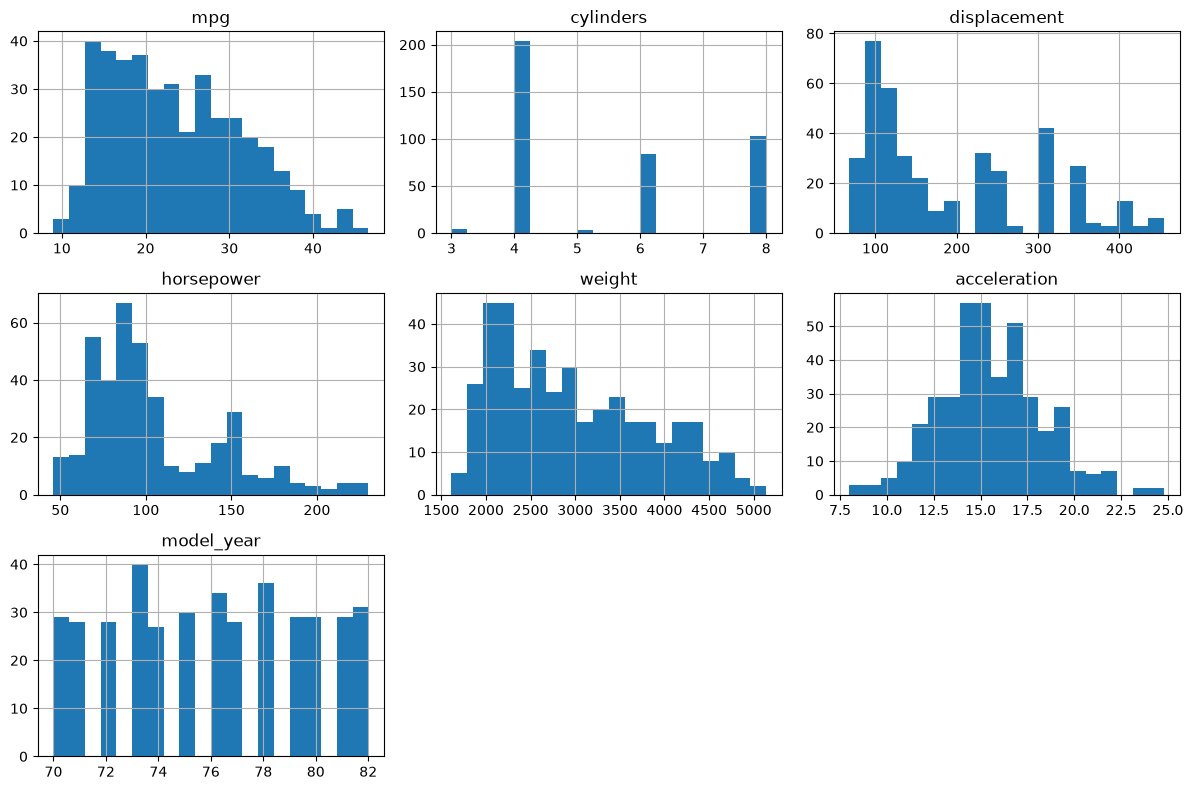

In [71]:
df.hist(bins=20, figsize=(12, 8))
plt.tight_layout()
plt.show()

In [72]:
correlaciones = df.corr(numeric_only=True)

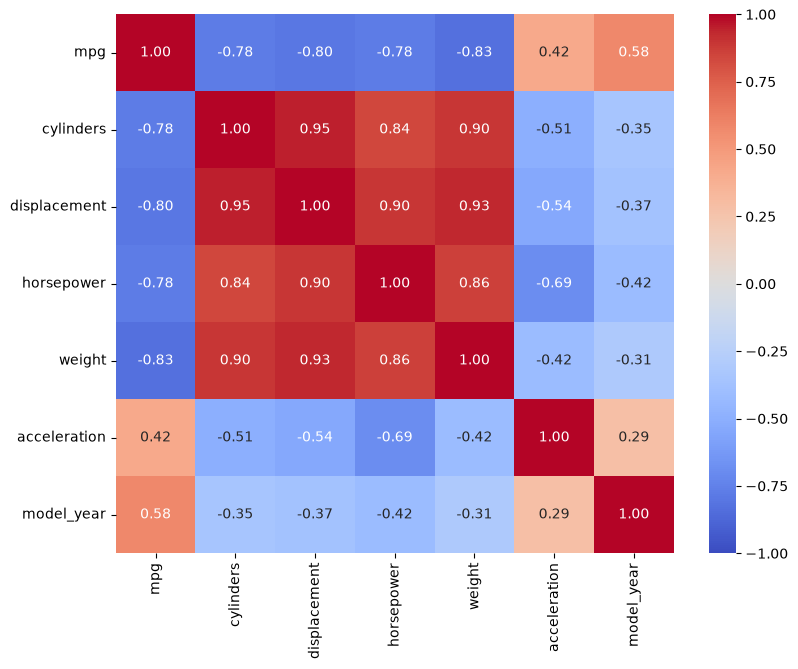

In [73]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)

plt.show()

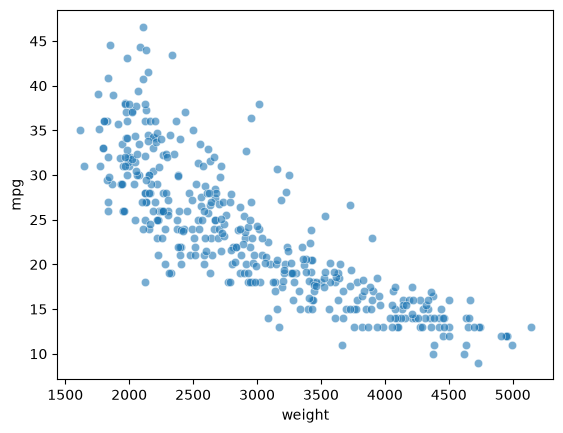

In [74]:
sns.scatterplot(data=df, x="weight", y="mpg", alpha=0.6)
plt.show()

## Limpieza y Preparación

In [75]:
# Tu código aquí
#cuantas fials y columnas tenemos 
print("Filas y Columnas ", df.shape)

#tipos de datos que tenemos
df.info()

Filas y Columnas  (398, 9)
<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [76]:
#donde hay nulos
df.isna().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

Desde ahorita voy pensando en rellenar esos 6 nulos con la mediana

In [77]:
#hay duplicados
df.duplicated().sum()

np.int64(0)

In [78]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [79]:
#cuantos carros hay por cada pais que lo facbrica
df['origin'].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

In [80]:
#nombres diferentes de los carros 
print("Nombres diferentes de los carros ", df['name'].nunique())

df["name"].head(10)

Nombres diferentes de los carros  305


0    chevrolet chevelle malibu
1            buick skylark 320
2           plymouth satellite
3                amc rebel sst
4                  ford torino
5             ford galaxie 500
6             chevrolet impala
7            plymouth fury iii
8             pontiac catalina
9           amc ambassador dpl
Name: name, dtype: str

La verdad son muchos nombres o medolos de los carros, entons no los voy a incluir para entrenar al modelo

In [81]:
X = df.drop(columns=["mpg", "name"])
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Entrenamiento:", X_train.shape, y_train.shape)
print("Test:", X_test.shape, y_test.shape)

Entrenamiento: (318, 7) (318,)
Test: (80, 7) (80,)


regresión simple

In [82]:
modelo_simple = LinearRegression()

modelo_simple.fit(X_train[["weight"]], y_train)

beta_0 = modelo_simple.intercept_
beta_1 = modelo_simple.coef_[0]

print(f"Intercepto: {beta_0:.3f}")
print(f"Coeficiente de weight: {beta_1:.5f}")
print(f"Cambio estimado por 100 libras más: {beta_1 * 100:.2f} MPG")

Intercepto: 46.782
Coeficiente de weight: -0.00781
Cambio estimado por 100 libras más: -0.78 MPG


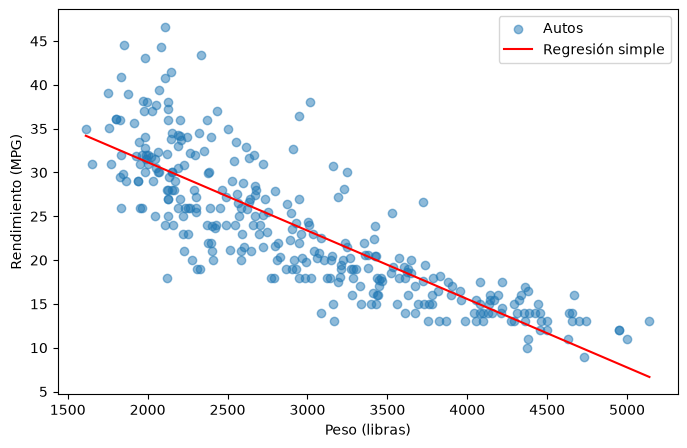

In [83]:
pesos = X_train[["weight"]].sort_values("weight")
pred_recta = modelo_simple.predict(pesos)

plt.figure(figsize=(8, 5))
plt.scatter(X_train["weight"], y_train, alpha=0.5, label="Autos")
plt.plot(pesos["weight"], pred_recta, color="red", label="Regresión simple")
plt.xlabel("Peso (libras)")
plt.ylabel("Rendimiento (MPG)")
plt.legend()
plt.show()

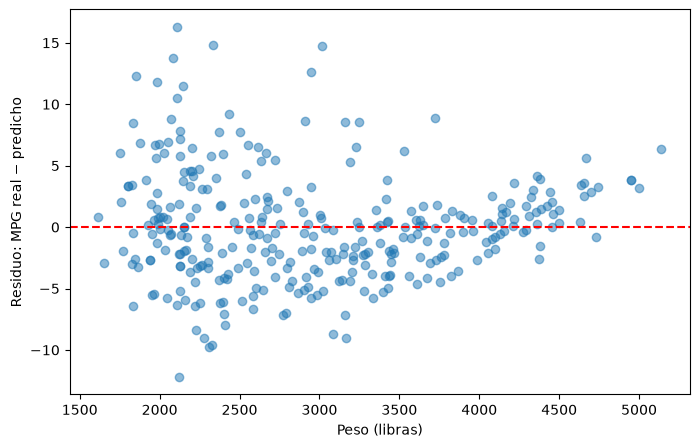

In [84]:
pred_train = modelo_simple.predict(X_train[["weight"]])
residuos = y_train - pred_train

plt.figure(figsize=(8, 5))
plt.scatter(X_train["weight"], residuos, alpha=0.5)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Peso (libras)")
plt.ylabel("Residuo: MPG real − predicho")
plt.show()

In [85]:
print(f"MAE train: {mean_absolute_error(y_train, pred_train):.3f} MPG")
print(f"RMSE train: {root_mean_squared_error(y_train, pred_train):.3f} MPG")
print(f"R² train: {r2_score(y_train, pred_train):.3f}")

MAE train: 3.359 MPG
RMSE train: 4.448 MPG
R² train: 0.684


| Métrica | Interpretación |
|---|---|
| **MAE** | Error absoluto promedio. Un MAE de 3 significa equivocarse, en promedio, 3 MPG. |
| **RMSE** | También se expresa en MPG, pero penaliza más los errores grandes. |
| **R²** | Compara el modelo con predecir siempre la media: 1 representa predicciones perfectas y 0 equivale a esa referencia. **No es un porcentaje de aciertos.** |

In [86]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scores_simple = cross_val_score(
    modelo_simple,
    X_train[["weight"]],
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

rmse_cv_simple = -scores_simple

print("RMSE en cada partición:", rmse_cv_simple.round(3))
print(f"RMSE promedio de validación: {rmse_cv_simple.mean():.3f} MPG")
print(f"Desviación entre particiones: {rmse_cv_simple.std():.3f} MPG")

RMSE en cada partición: [4.371 4.755 4.59  4.193 4.554]
RMSE promedio de validación: 4.493 MPG
Desviación entre particiones: 0.193 MPG


con las 7 carac

In [87]:
numericas = [
    "cylinders", "displacement", "horsepower",
    "weight", "acceleration", "model_year",
]

preparacion_numerica = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler()),
])

preparacion = ColumnTransformer([
    ("numericas", preparacion_numerica, numericas),
    ("origen", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
    ), ["origin"]),
])

In [88]:
modelo_multiple = Pipeline([
    ("preparacion", preparacion),
    ("regresion", LinearRegression()),
])

modelo_multiple.fit(X_train, y_train)

pred_train_multiple = modelo_multiple.predict(X_train)

print(f"MAE train: {mean_absolute_error(y_train, pred_train_multiple):.3f} MPG")
print(f"RMSE train: {root_mean_squared_error(y_train, pred_train_multiple):.3f} MPG")
print(f"R² train: {r2_score(y_train, pred_train_multiple):.3f}")

MAE train: 2.605 MPG
RMSE train: 3.370 MPG
R² train: 0.819


In [89]:
scores_multiple = cross_val_score(
    modelo_multiple,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

rmse_cv_multiple = -scores_multiple

print("RMSE por partición:", rmse_cv_multiple.round(3))
print(f"RMSE promedio de validación: {rmse_cv_multiple.mean():.3f} MPG")
print(f"Desviación entre particiones: {rmse_cv_multiple.std():.3f} MPG")

RMSE por partición: [3.6   3.798 3.263 3.188 3.539]
RMSE promedio de validación: 3.478 MPG
Desviación entre particiones: 0.224 MPG


In [90]:
preparacion_ajustada = modelo_multiple.named_steps["preparacion"]
regresion_ajustada = modelo_multiple.named_steps["regresion"]

coeficientes = pd.DataFrame({
    "variable": preparacion_ajustada.get_feature_names_out(),
    "coeficiente": regresion_ajustada.coef_,
})

print(f"Intercepto: {regresion_ajustada.intercept_:.3f}")
coeficientes.round(3)

Intercepto: 25.482


,variable,coeficiente
0,numericas__cylinders,-0.279
1,numericas__displacement,2.036
2,numericas__horsepower,-0.545
3,numericas__weight,-5.912
4,numericas__acceleration,0.186
5,numericas__model_year,2.971
6,origen__origin_japan,-0.274
7,origen__origin_usa,-2.948


Ridge

In [91]:
modelo_ridge = Pipeline([
    ("preparacion", clone(preparacion)),
    ("regresion", Ridge(alpha=1.0)),
])

modelo_ridge.fit(X_train, y_train)

rmse_cv_ridge = -cross_val_score(
    modelo_ridge,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

print(f"RMSE CV Ridge: {rmse_cv_ridge.mean():.3f} MPG")

RMSE CV Ridge: 3.471 MPG


laso

In [92]:
modelo_lasso = Pipeline([
    ("preparacion", clone(preparacion)),
    ("regresion", Lasso(alpha=0.01, max_iter=10000)),
])

modelo_lasso.fit(X_train, y_train)

rmse_cv_lasso = -cross_val_score(
    modelo_lasso,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

print(f"RMSE CV Lasso: {rmse_cv_lasso.mean():.3f} MPG")

RMSE CV Lasso: 3.464 MPG


Polinomial

In [93]:
preparacion_polinomial = ColumnTransformer([
    ("numericas", Pipeline([
        ("base", clone(preparacion_numerica)),
        ("polinomios", PolynomialFeatures(degree=2, include_bias=False)),
        ("escalador_poli", StandardScaler()),
    ]), numericas),

    ("origen", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
    ), ["origin"]),
])

modelo_polinomial = Pipeline([
    ("preparacion", preparacion_polinomial),
    ("regresion", LinearRegression()),
])

modelo_polinomial.fit(X_train, y_train)

rmse_cv_polinomial = -cross_val_score(
    modelo_polinomial,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

print(f"RMSE CV polinomial: {rmse_cv_polinomial.mean():.3f} MPG")

RMSE CV polinomial: 3.091 MPG


In [94]:
modelo_ransac = Pipeline([
    ("preparacion", clone(preparacion)),
    ("regresion", RANSACRegressor(
        estimator=LinearRegression(),
        random_state=42,
        max_trials=1000,
    )),
])

modelo_ransac.fit(X_train, y_train)

rmse_cv_ransac = -cross_val_score(
    modelo_ransac,
    X_train,
    y_train,
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

print(f"RMSE CV RANSAC: {rmse_cv_ransac.mean():.3f} MPG")

RMSE CV RANSAC: 3.724 MPG


In [95]:
busqueda_polinomial = GridSearchCV(
    estimator=clone(modelo_polinomial),
    param_grid={
        "preparacion__numericas__polinomios__degree": [1, 2, 3],
    },
    cv=cv,
    scoring="neg_root_mean_squared_error",
)

busqueda_polinomial.fit(X_train, y_train)

modelo_polinomial_opt = busqueda_polinomial.best_estimator_

print("Mejor configuración:", busqueda_polinomial.best_params_)
print(f"Mejor RMSE CV: {-busqueda_polinomial.best_score_:.3f} MPG")

Mejor configuración: {'preparacion__numericas__polinomios__degree': 2}
Mejor RMSE CV: 3.091 MPG


In [96]:
resultados_grados = pd.DataFrame({
    "Grado": busqueda_polinomial.cv_results_[
        "param_preparacion__numericas__polinomios__degree"
    ],
    "RMSE CV": -busqueda_polinomial.cv_results_["mean_test_score"],
    "Desviación CV": busqueda_polinomial.cv_results_["std_test_score"],
})

resultados_grados.sort_values("RMSE CV").round(3)

,Grado,RMSE CV,Desviación CV
1,2,3.091,0.265
0,1,3.478,0.224
2,3,5.451,3.040


In [97]:
modelos = {
    "Simple": (modelo_simple, rmse_cv_simple),
    "Lineal múltiple": (modelo_multiple, rmse_cv_multiple),
    "Ridge": (modelo_ridge, rmse_cv_ridge),
    "Lasso": (modelo_lasso, rmse_cv_lasso),
    "Polinomial (grado 2)": (modelo_polinomial_opt, rmse_cv_polinomial),
    "RANSAC": (modelo_ransac, rmse_cv_ransac),
}

filas = []

for nombre, (modelo, errores_cv) in modelos.items():
    columnas = ["weight"] if nombre == "Simple" else X_train.columns

    pred_entrenamiento = modelo.predict(X_train[columnas])
    pred_test = modelo.predict(X_test[columnas])

    filas.append({
        "Modelo": nombre,
        "RMSE train": root_mean_squared_error(y_train, pred_entrenamiento),
        "RMSE CV": errores_cv.mean(),
        "Desviación CV": errores_cv.std(),
        "RMSE test": root_mean_squared_error(y_test, pred_test),
        "MAE test": mean_absolute_error(y_test, pred_test),
        "R² test": r2_score(y_test, pred_test),
    })

reporte = (
    pd.DataFrame(filas)
    .set_index("Modelo")
    .sort_values("RMSE CV")
)

reporte.round(3)

,RMSE train,RMSE CV,Desviación CV,RMSE test,MAE test,R² test
Modelo,,,,,,
Polinomial (grado 2),2.648,3.091,0.265,2.598,1.921,0.875
Lasso,3.372,3.464,0.209,2.894,2.273,0.844
Ridge,3.371,3.471,0.206,2.886,2.281,0.845
Lineal múltiple,3.370,3.478,0.224,2.888,2.288,0.845
RANSAC,3.869,3.724,0.155,3.056,2.242,0.826
Simple,4.448,4.493,0.193,3.859,3.118,0.723


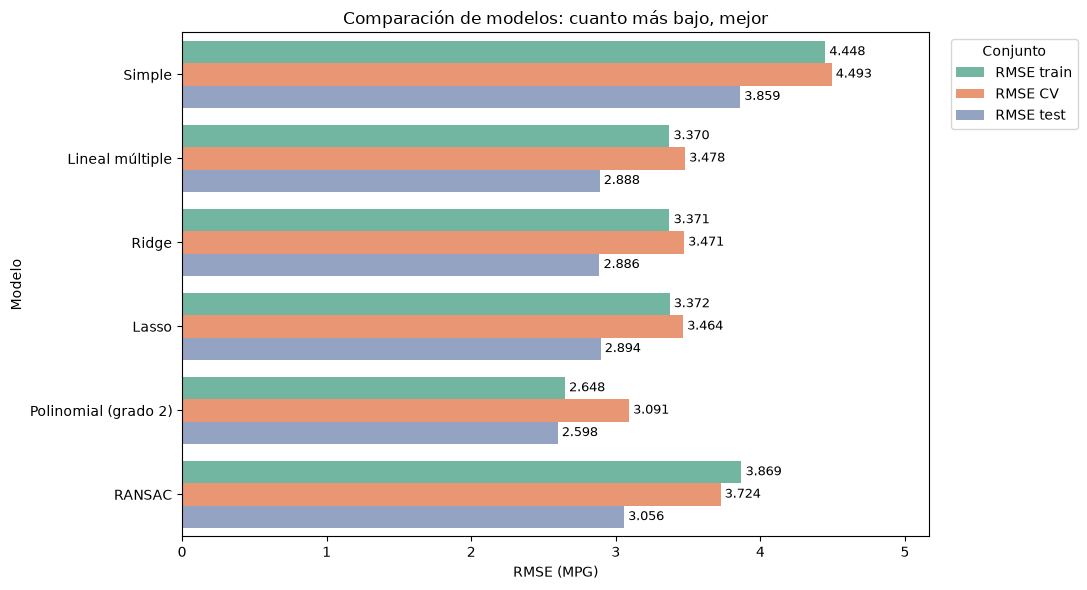

In [102]:
reporte_largo = (
    reporte[["RMSE train", "RMSE CV", "RMSE test"]]
    .reset_index()
    .melt(
        id_vars="Modelo",
        var_name="Conjunto",
        value_name="RMSE",
    )
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=reporte_largo,
    x="RMSE",
    y="Modelo",
    hue="Conjunto",
    order=list(modelos),
    palette="Set2",
    errorbar=None,
)

for contenedor in ax.containers:
    ax.bar_label(contenedor, fmt="%.3f", padding=3, fontsize=9)

ax.set_xlim(0, reporte_largo["RMSE"].max() * 1.15)
ax.set_xlabel("RMSE (MPG)")
ax.set_title("Comparación de modelos: cuanto más bajo, mejor")
ax.legend(title="Conjunto", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

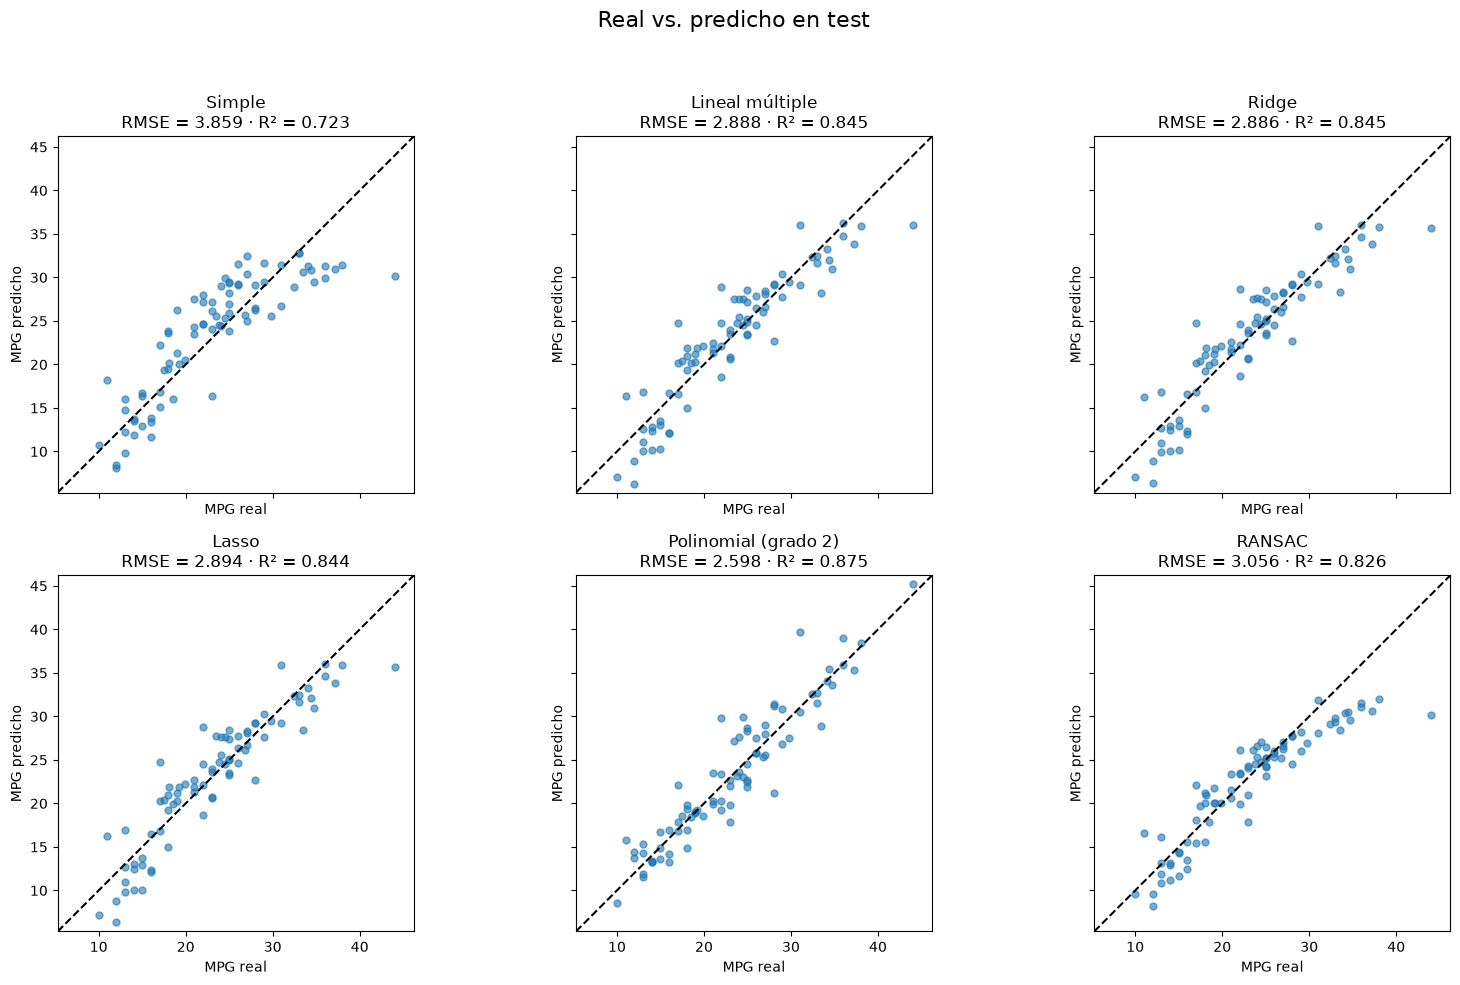

In [103]:
predicciones_test = {}
minimo = y_test.min()
maximo = y_test.max()

for nombre, (modelo, _) in modelos.items():
    columnas = ["weight"] if nombre == "Simple" else X_test.columns
    pred = modelo.predict(X_test[columnas])

    predicciones_test[nombre] = pred
    minimo = min(minimo, pred.min())
    maximo = max(maximo, pred.max())

limites = [minimo - 1, maximo + 1]

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 10),
    sharex=True,
    sharey=True,
)

for (nombre, pred), ax in zip(predicciones_test.items(), axes.flat):
    rmse = reporte.loc[nombre, "RMSE test"]
    r2 = reporte.loc[nombre, "R² test"]

    ax.scatter(y_test, pred, alpha=0.6, s=25)
    ax.plot(limites, limites, "k--")

    ax.set_title(f"{nombre}\nRMSE = {rmse:.3f} · R² = {r2:.3f}")
    ax.set(
        xlabel="MPG real",
        ylabel="MPG predicho",
        xlim=limites,
        ylim=limites,
    )
    ax.set_aspect("equal", adjustable="box")

fig.suptitle("Real vs. predicho en test", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Conclusiones
Elegiria el modelo con regresión polinomial ya que obtuvo un mejor desempeño tanto en train como en test.